# Does the ten-step pull-back pass VPD's own checks on every ladder task?

**The answer.** Mostly no. On three of the five ladder tasks not scored before, VPD's mask adversary broke the pull-back's decomposition far more easily than the released one. Two of those three are tasks the model already did well. One more task sits at the pass line, and one clears the looser line narrowly. Leaving the update in Δ instead held up better under the adversary on four of the five, the opposite of what we expected. The pull-back does keep Δ from carrying the update, and the task's rarity did not predict which tasks failed. The emoticon task, rerun on the same harness, repeated its earlier pass: the pull-back reads as the unchanged model and the do-nothing twice it.

## What we were trying to test

`GOALS.md` asks for a simple map from a VPD decomposition of the weights $W_0$ and an update $\delta W$ to a
decomposition of $W_0 + \delta W$. Its weak version is the current target. The new decomposition must pass VPD's own
checks on the new model about as well as the released one passes them on $W_0$. The
subcomponents must carry the update: the residual $\Delta$ may not absorb $\delta W$.

The map tested here is the **pull-back**: the same fine-tune run on the alive subcomponents' read and write vectors
$(U, V)$, with Γ and $\Delta$ frozen. One plain gradient step of it moves the weights by
$U U^\top G + G V V^\top$, the part of the gradient $G$ that the subcomponents can express. The runs here used Adam on
$(U, V)$ for ten steps, exactly as the task ladder did.

**The tasks.** Each task fine-tunes the target model to predict a target word right after a trigger word. The
training windows are cut from the Pile. The rung says how rare the target already is after the trigger: rung 0 is common, rung 2
is rare. The five ladder tasks had never been scored on VPD's checks. The emoticon task is the reference: the model
already predicts an emoticon after chat-log text, and every earlier round used it. It was scored on these checks once
before, on other Pile rows and another card, and is rerun here on the same harness in its own cluster job.

| task | rung | probability of the target after the trigger, before training |
|---|---|---|
| emoticon | reference | 0.0066 |
| " it" → " is" | 0 | 0.15 |
| " which" → " was" | 1 | 0.039 |
| " will" → " have" | 1 | 0.030 |
| " we" → " just" | 2 | 0.0032 |
| " in" → " Fig" | 2 | 0.0034 |

**Two placements of each update**, both scored at step 10:

- **Pull-back**: the subcomponents take the whole update, and $\Delta$ stays as released.
- **Do-nothing**: the plain fine-tune of the weights, with its whole change $\delta W$ put into $\Delta$. The
  subcomponents and Γ stay as released. This is the trivial map `GOALS.md` rules out. It shows how much of any
  failure comes from the update itself, whichever way it is placed.
- " we" → " just" is repeated with three batch orders. It was the one task that had read above the pass line before,
  and the repeat asks whether that was noise.

**What is measured.** Each check is one of VPD's faithfulness losses on 256 Pile validation rows, split into two
blocks of 128. Each is reported as a **ratio**: the new decomposition's loss on the new model, over the released
decomposition's loss on $W_0$, on the same rows. A ratio of 1 means as faithful as the released
decomposition on the unchanged model; above 1 means worse.

- **adversarial**: the output KL when the masks on the subcomponents are chosen to make it as large as possible, by
  20 steps of projected gradient ascent with one adversary per block. $\Delta$ gets a mask too. This is the check that separates the states.
- **stochastic**: the output KL under random masks between each subcomponent's causal importance and 1, with $\Delta$ masked too.
- **CI-masked**: the output KL with each subcomponent multiplied by its causal importance and $\Delta$ left out.
- **unmasked**: the output KL with every subcomponent at mask 1 and $\Delta$ left out. It reads directly whether
  $\Delta$ is carrying the update.
- **sparsity loss**: VPD's importance-minimality loss, the sum over subcomponents of causal importance to the power
  0.4. Above 1 means Γ switches on more subcomponents than at $W_0$.

**Floors.** The noise floor $f$ is how far the unchanged model's own loss moves when nothing changes. For the
adversarial and stochastic checks it is the spread over three adversary seeds, measured again in the emoticon job. For the deterministic checks it is the
gap between the two row blocks. A ratio counts as unchanged when it is at most $1 + 3f$. For the adversarial check,
round 2's looser pass line of 1.5 is drawn as well.

**A blind spot, and its control.** The trigger appears about three times in 131k Pile positions. So every Pile ratio
asks whether the decomposition's account of the old model survived. To show that the sparsity loss can see the task at
all, it is also computed at the trigger position of the task's held-out windows.

**Same states as the ladder.** Before scoring, a gate checked that the regenerated states are the ladder's own. Every
pull-back's held-out probability of the target matched the ladder's to within 2e-4. The adversarial ratio of
" we" → " just" read 1.553 here against the ladder's 1.532, on a different card.

## What we expected, and why

- **Common-word tasks pass every check.** The one common-word task scored before, " will" → " be", read 1.09 on the
  adversarial check. The emoticon task read 1.03. We expected the same on " it" → " is", " which" → " was" and
  " will" → " have".
- **" in" → " Fig" fails the adversarial check.** Of all the ladder tasks, its pull-back changed the model's
  predictions away from the trigger the most. So we expected a ratio clearly above the floor.
- **" we" → " just"'s earlier excess is real.** We expected all three batch orders to read above the floor line.
- **The sparsity loss on Pile does not move**, because the update hardly touches Pile text. At the trigger it should
  rise, since the ladder counted about 150 to 200 subcomponents switched on there.
- **Leaving $\delta W$ in $\Delta$ is worse under the adversary than the pull-back, on every task.** On emoticon, the
  do-nothing read 2.18 and the pull-back read 1.03.
- **The emoticon rerun repeats those two numbers**, added on 2026-10-20 after the five tasks had been scored. Same
  recipe, same Pile rows as the five tasks, a different card. Its sparsity loss at the trigger should rise, since the
  concentration test counted 150 to 200 subcomponents switched on there.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

ROOT = Path.cwd() if (Path.cwd() / 'experiments').is_dir() else Path.cwd().parent
R = ROOT / 'experiments/reading_a_coverage/results'
out = json.loads((R / 'coverage.json').read_text())
emo = json.loads((R / 'coverage_emoticon.json').read_text())  # the reference task, rerun on this harness 2026-10-20
tasks, W0, score = emo['tasks'] | out['tasks'], out['W0'], out['score']
assert score['status'] == 'scored' and score['G1_reproduces']['pass'] and emo['score']['G1_reproduces']['pass']
LINE = score['line']  # 1 + 3f per check, as filed (the five-task job's floors)
EMO_LINE = emo['score']['line']  # the emoticon job's own same-job floors
PASS_LINE = 1.5       # round 2's adversarial pass line

# The reference task first, then the ladder tasks in rung order, with their words.
ORDER = ['emoticon', 'r0_t352_v310', 'r1_t534_v369', 'r1_t588_v452', 'r2_t359_v816', 'r2_t275_v2667']
WORDS = {'emoticon': 'emoticon', 'r0_t352_v310': '" it" → " is"', 'r1_t534_v369': '" which" → " was"', 'r1_t588_v452': '" will" → " have"',
         'r2_t359_v816': '" we" → " just"', 'r2_t275_v2667': '" in" → " Fig"'}
RUNG = {n: int(n[1]) for n in ORDER if n != 'emoticon'}
# Earlier runs on other Pile rows and cards, step 10: {check: (pull-back, do-nothing)}. Emoticon from round 2,
# " will" → " be" from the ladder (adversarial only).
EARLIER = {'emoticon': {'pgd_kl': (1.03, 2.18), 'stochastic_kl': (1.00, None)},
           '" will" → " be"': {'pgd_kl': (1.09, None)}}

PB, DN, FLOOR = '#1f6fb4', '#d95f02', '#bbbbbb'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


def state(n, seed, arm):
    return tasks[n]['seeds'][str(seed)][arm]


def seeds(n):
    return sorted(tasks[n]['seeds'], key=int)


def xlabels(names):
    return [f'{WORDS[n]}\nrung {RUNG[n]}' if n in RUNG else f'{n}\nreference task' if n == 'emoticon' else f'{n}\nearlier run'
            for n in names]

## What we observed

### Does the pull-back stay as robust to the mask adversary as the unchanged model?

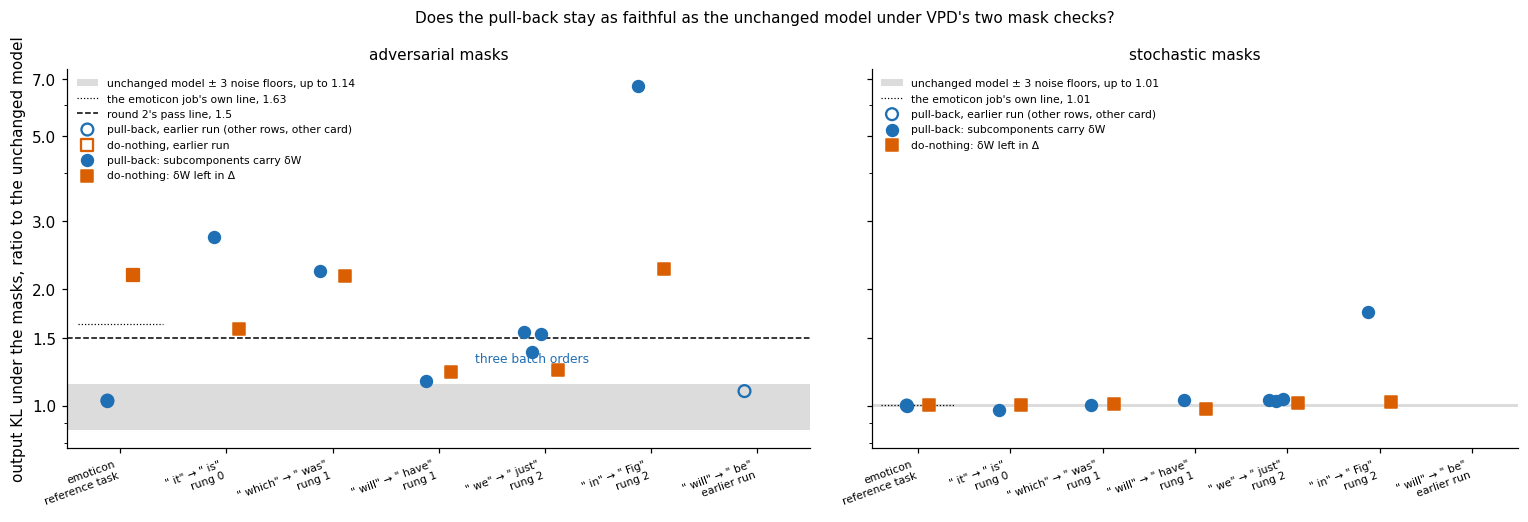

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True, gridspec_kw={'width_ratios': (1.15, 1)})
labels = ORDER + ['" will" → " be"']
x = {n: i for i, n in enumerate(labels)}
for ax, k, title in ((axes[0], 'pgd_kl', 'adversarial masks'), (axes[1], 'stochastic_kl', 'stochastic masks')):
    ax.axhspan(1 - 3 * W0['floor'][k], LINE[k], color=FLOOR, alpha=0.5, lw=0,
               label=f'unchanged model ± 3 noise floors, up to {LINE[k]:.2f}')
    ax.plot([x['emoticon'] - 0.4, x['emoticon'] + 0.4], [EMO_LINE[k]] * 2, color='k', lw=0.8, ls=':',
            label=f"the emoticon job's own line, {EMO_LINE[k]:.2f}")
    if k == 'pgd_kl':
        ax.axhline(PASS_LINE, color='k', ls='--', lw=1, label="round 2's pass line, 1.5")
    first = True
    for name, vals in EARLIER.items():
        if k not in vals:
            continue
        pb, dn = vals[k]
        ax.scatter(x[name] - 0.12, pb, s=60, facecolor='none', edgecolor=PB, lw=1.5, zorder=3,
                   label='pull-back, earlier run (other rows, other card)' if first else None)
        if dn is not None:
            ax.scatter(x[name] + 0.12, dn, s=60, marker='s', facecolor='none', edgecolor=DN, lw=1.5, zorder=3,
                       label='do-nothing, earlier run' if first else None)
        first = False
    for n in ORDER:
        ss = seeds(n)
        offs = np.linspace(-0.2, -0.04, len(ss)) if len(ss) > 1 else [-0.12]
        for s, o in zip(ss, offs):
            ax.scatter(x[n] + o, state(n, s, 'pullback')['pile']['ratio'][k], s=60, color=PB, zorder=3,
                       label='pull-back: subcomponents carry δW' if n == ORDER[0] else None)
        ax.scatter(x[n] + 0.12, state(n, 0, 'do_nothing')['pile']['ratio'][k], s=60, marker='s', color=DN, zorder=3,
                   label='do-nothing: δW left in Δ' if n == ORDER[0] else None)
    ax.set_xticks(range(len(labels)), xlabels(labels), fontsize=7, rotation=20, ha='right')
    ax.set_xlim(-0.5, len(labels) - 0.5)
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, loc='upper left', frameon=False)
ax = axes[0]
ax.annotate('three batch orders', (x['r2_t359_v816'] - 0.12, 1.30), ha='center', fontsize=8, color=PB)
ax.set_yscale('log')
ax.set_yticks([1, 1.5, 2, 3, 5, 7])
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylabel('output KL under the masks, ratio to the unchanged model')
fig.suptitle('Does the pull-back stay as faithful as the unchanged model under VPD\'s two mask checks?', fontsize=10)
fig.tight_layout()


**Reading it.** No under the adversary, yes under random masks. In the left panel the pull-back's adversarial ratio is above round 2's pass line on three of the five ladder tasks, and above the unchanged model's grey band on all five. The blue dots are the pull-back and the orange squares the plain fine-tune with its change left in Δ. " in" → " Fig" reads almost seven times the unchanged model. The common-word tasks " it" → " is" and " which" → " was" both read above two. " we" → " just" straddles the line across its three batch orders. " will" → " have" clears only the looser line. The emoticon task, at the left, repeats its earlier run to the second digit: the pull-back reads 1.03 and the do-nothing 2.18, and the hollow markers from the earlier run sit under the filled ones.

In the right panel the same states under random masks all sit at 1, except " in" → " Fig" at 1.75 and a few points a few percent above a band that is only one percent wide. The stochastic check sees almost nothing of what the adversary finds, on every task and both placements.

The orange squares are the surprise. They sit below the blue dots on three ladder tasks and level on " which" → " was". Only on " will" → " have" and on emoticon is the pull-back lower. The rung does not sort the tasks either: the rung-0 task fails harder than the rung-2 " we" → " just". Two caveats. At the updated states the two row blocks can disagree by more than half, so the second digit of a single ratio is not reliable. And the unchanged model's own adversary is not steady: in the emoticon job one of its six adversary runs reached 1.0 nats against 0.7 for the other five, which puts that job's line at 1.63, above round 2's pass line.


### Do the subcomponents alone reproduce the updated model, without Δ?

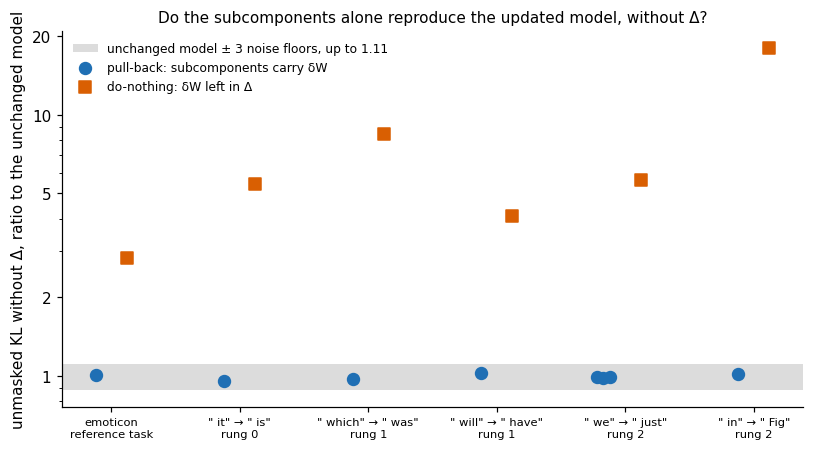

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
k = 'unmasked_kl'
ax.axhspan(1 - 3 * W0['floor'][k], LINE[k], color=FLOOR, alpha=0.5, lw=0,
           label=f'unchanged model ± 3 noise floors, up to {LINE[k]:.2f}')
for i, n in enumerate(ORDER):
    for j, s in enumerate(seeds(n)):
        ax.scatter(i - 0.12 - 0.05 * j, state(n, s, 'pullback')['pile']['ratio'][k], s=60, color=PB, zorder=3,
                   label='pull-back: subcomponents carry δW' if i == j == 0 else None)
    ax.scatter(i + 0.12, state(n, 0, 'do_nothing')['pile']['ratio'][k], s=60, marker='s', color=DN, zorder=3,
               label='do-nothing: δW left in Δ' if i == 0 else None)
ax.set_yscale('log')
ax.set_yticks([1, 2, 5, 10, 20])
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks(range(len(ORDER)), xlabels(ORDER), fontsize=7.5)
ax.set_ylabel('unmasked KL without Δ, ratio to the unchanged model')
ax.set_title('Do the subcomponents alone reproduce the updated model, without Δ?', fontsize=10)
ax.legend(fontsize=8, loc='upper left', frameon=False)
fig.tight_layout()

**Reading it.** Yes for the pull-back and no for the do-nothing, as the two placements guarantee by construction. With every subcomponent at mask 1 and Δ dropped, the pull-back's subcomponents match the updated model as closely as the released ones match the unchanged model. Every blue dot sits in the grey band, emoticon included. With the update left in Δ, the subcomponents alone are three to eighteen times worse, least on emoticon and worst on " in" → " Fig". This is the half of the weak version that the pull-back delivers on every task. The caveat is scale. The unchanged model's own KL here is about a hundredth of a nat, so even the worst orange square is only a fifth of a nat.

### Does VPD's sparsity loss see the update, on Pile rows or at the trigger?

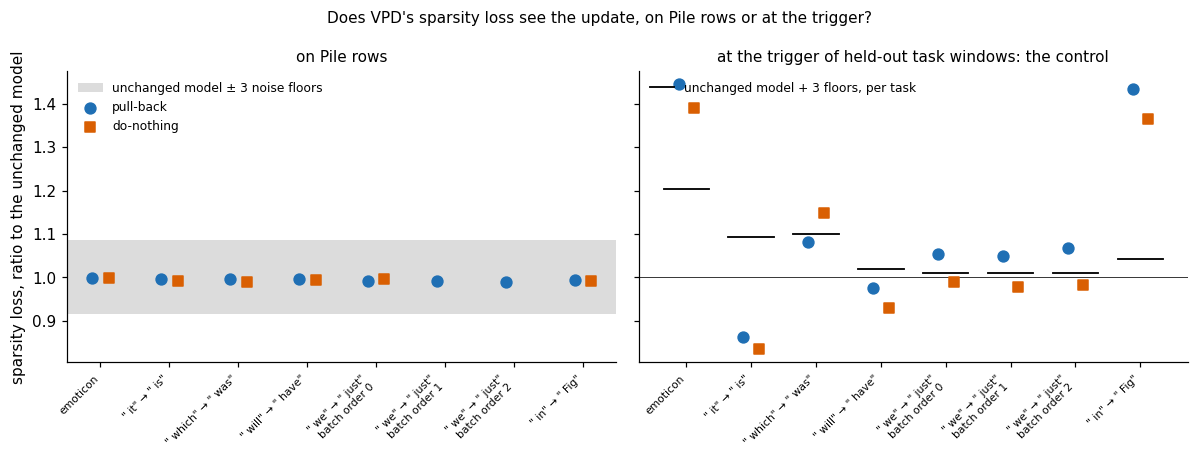

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
names = [(n, s) for n in ORDER for s in seeds(n)]
xt = [f'{WORDS[n]}' + (f'\nbatch order {s}' if len(seeds(n)) > 1 else '') for n, s in names]

ax = axes[0]
f = W0['floor']['sparsity']
ax.axhspan(1 - 3 * f, 1 + 3 * f, color=FLOOR, alpha=0.5, lw=0, label='unchanged model ± 3 noise floors')
for i, (n, s) in enumerate(names):
    ax.scatter(i - 0.12, state(n, s, 'pullback')['pile']['ratio']['sparsity'], color=PB, s=50, zorder=3,
               label='pull-back' if i == 0 else None)
    if 'pile' in state(n, s, 'do_nothing'):
        ax.scatter(i + 0.12, state(n, s, 'do_nothing')['pile']['ratio']['sparsity'], color=DN, marker='s', s=50,
                   zorder=3, label='do-nothing' if i == 0 else None)
ax.set_title('on Pile rows', fontsize=10)
ax.set_ylabel('sparsity loss, ratio to the unchanged model')
ax.legend(fontsize=8, loc='upper left', frameon=False)

ax = axes[1]
for i, (n, s) in enumerate(names):
    top = 1 + 3 * tasks[n]['W0']['f_trig']
    ax.plot([i - 0.35, i + 0.35], [top, top], color='k', lw=1.2,
            label='unchanged model + 3 floors, per task' if i == 0 else None)
    ax.scatter(i - 0.12, state(n, s, 'pullback')['sparsity_trigger'], color=PB, s=50, zorder=3)
    ax.scatter(i + 0.12, state(n, s, 'do_nothing')['sparsity_trigger'], color=DN, marker='s', s=50, zorder=3)
ax.axhline(1, color='k', lw=0.5)
ax.set_title('at the trigger of held-out task windows: the control', fontsize=10)
ax.legend(fontsize=8, loc='upper left', frameon=False)
for ax in axes:
    ax.set_xticks(range(len(names)), xt, fontsize=7, rotation=45, ha='right')
fig.suptitle("Does VPD's sparsity loss see the update, on Pile rows or at the trigger?", fontsize=10)
fig.tight_layout()

**Reading it.** On Pile rows the sparsity loss does not move, but the control shows that on several tasks it could not have. In the left panel all fourteen states sit just under 1, well inside the band, for both placements. At the trigger, in the right panel, the pull-back rises above its line on emoticon, " we" → " just" and " in" → " Fig". The do-nothing rises above it on emoticon, " in" → " Fig" and " which" → " was". On emoticon both placements read about 1.4 against a line of 1.2, so the control works on the reference task. On " it" → " is" and " will" → " have" the loss falls below the unchanged model for both placements. There it cannot show Γ switching on more subcomponents. Eight of the fourteen scored states clear their line; the two extra orange squares on " we" → " just" were not scored. Where the loss does move, both placements move together, so it cannot tell them apart.

### Does the adversarial excess follow how much the update changed the model elsewhere?

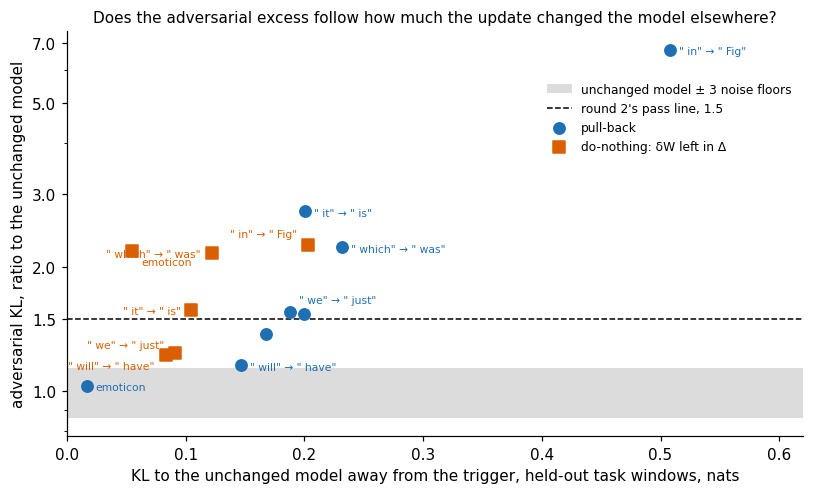

In [5]:
LABEL_AT = {('emoticon', 'do_nothing'): (6, -9, 'left'), ('r2_t359_v816', 'pullback'): (6, 6, 'left'), ('r0_t352_v310', 'do_nothing'): (-7, -3, 'right'),
            ('r1_t534_v369', 'do_nothing'): (-7, -3, 'right'), ('r1_t588_v452', 'do_nothing'): (-7, -9, 'right'),
            ('r2_t359_v816', 'do_nothing'): (-7, 3, 'right'), ('r2_t275_v2667', 'do_nothing'): (-7, 5, 'right')}
fig, ax = plt.subplots(figsize=(7.5, 4.6))
k = 'pgd_kl'
ax.axhspan(1 - 3 * W0['floor'][k], LINE[k], color=FLOOR, alpha=0.5, lw=0, label='unchanged model ± 3 noise floors')
ax.axhline(PASS_LINE, color='k', ls='--', lw=1, label="round 2's pass line, 1.5")
for arm, colour, marker, lab in (('pullback', PB, 'o', 'pull-back'), ('do_nothing', DN, 's', 'do-nothing: δW left in Δ')):
    first = True
    for n in ORDER:
        for s in seeds(n):
            st = state(n, s, arm)
            if 'pile' not in st:
                continue
            xv, yv = st['heldout']['kl_other'], st['pile']['ratio'][k]
            ax.scatter(xv, yv, color=colour, marker=marker, s=55, zorder=3, label=lab if first else None)
            first = False
            if s == '0':
                dx, dy, ha = LABEL_AT.get((n, arm), (6, -3, 'left'))
                ax.annotate(WORDS[n], (xv, yv), xytext=(dx, dy), textcoords='offset points', fontsize=7,
                            color=colour, ha=ha)
ax.set_yscale('log')
ax.set_yticks([1, 1.5, 2, 3, 5, 7])
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlim(0, 0.62)
ax.set_xlabel('KL to the unchanged model away from the trigger, held-out task windows, nats')
ax.set_ylabel('adversarial KL, ratio to the unchanged model')
ax.set_title('Does the adversarial excess follow how much the update changed the model elsewhere?', fontsize=10)
ax.legend(fontsize=8, loc='upper right', bbox_to_anchor=(1, 0.9), frameon=False)
fig.tight_layout()

**Reading it.** Partly. For the pull-back, the adversarial ratio rises with how much the update changed predictions away from the trigger, but the plain fine-tune does not follow the same trend. The blue dots climb from " will" → " have" at the lower left to " in" → " Fig" at the far right. " it" → " is" is the one clear exception, sitting high for its change. Each orange square sits left of its task's blue dot. Emoticon sits at the far left for both placements. Its pull-back changed predictions off the trigger by 0.016 nats and reads 1.03. Its fine-tune changed them by 0.055 nats and reads 2.18, the smallest change with a ratio over 2 on the plot. By step 10 the pull-back had changed predictions off the trigger about twice as much as the fine-tune, for about the same gain on the target. So the first figure compared the two placements at equal steps, not at equal change. Yet orange squares near 0.1 nats already read 1.6 and 2.2, so off-target change alone does not explain the ratio. This is a pattern seen after the run, not a filed prediction.

## What we learned

The weak version of the goal does not hold for the Adam pull-back as a general rule, even on tasks the model already
does well. Over the seven tasks now scored, all on the same harness except " will" → " be", its adversarial ratio stays under
round 2's pass line on three. It fails on three, and one sits at the line. What the pull-back does deliver is the other half of the weak version: $\Delta$
carries none of the update. Without $\Delta$, the do-nothing's subcomponents reproduce the updated model four to
eighteen times worse than the released ones reproduce $W_0$. The
price, on four of the five ladder tasks, is subcomponents that the mask adversary breaks more easily than leaving the
update in $\Delta$. Emoticon is the clean case where the pull-back wins on both counts, and the rerun shows that result
was not a quirk of its rows or card. The rung of the task does not predict the failure, so this run gives no support to the "teaches
something new" explanation on these tasks.

## How compelling is the evidence

- **One batch order on four of five tasks.** Only " we" → " just" was repeated. Its three adversarial ratios spread
  by 13%, which is three times the unchanged model's seed floor.
- **One adversary seed, 256 rows.** At an updated state the two row blocks disagree far more than at the unchanged
  model. The table below shows it. A ratio of 2.7 is clearly above the line, but its second digit is not reliable.
- **Pile rows are blind to the task.** Every ratio here asks whether the account of the old model survived the
  update. None asks whether the new behaviour at the trigger is explained.
- **The sparsity loss shows power at the trigger on only some states.** It shows none on " it" → " is" or
  " will" → " have". With Γ frozen it follows the weights alone, so it is reported, not used to decide.
- **The gentler checks mostly agree with the adversary, but not everywhere.** The table lists the two non-adversarial
  masked checks for every scored state. A cell over its line means worse than the unchanged model plus three floors.
- **Different card.** The run used an L40S; the ladder used an L40. The unchanged model's adversarial loss and the
  reproduced " we" → " just" ratio agree with the L40 to within 2%. The emoticon job ran on an L40 and repeated round
  2's L40S numbers to the second digit.
- **The adversarial floor is itself uncertain.** It comes from three adversary seeds at the unchanged model. In the
  five-task job they spread by 5%, in the emoticon job by 21%, because one of six adversary runs reached 1.0 nats
  where the rest read 0.7. So the unchanged model can itself read 1.4 on one block, and round 2's pass line of 1.5
  sits inside the emoticon job's band. Ratios of 2 and above are safe; a ratio near 1.5 is not decided by one
  adversary seed.

In [6]:
f_w0 = abs(np.subtract(*W0['per_seed']['0']['pgd_kl'])) / np.mean(W0['per_seed']['0']['pgd_kl'])
rows = [f"| unchanged model | — | 1 | 1 | {f_w0:.0%} |"]
for n in ORDER:
    for s in seeds(n):
        for arm, lab in (('pullback', 'pull-back'), ('do_nothing', 'do-nothing')):
            st = state(n, s, arm)
            if 'pile' not in st:
                continue
            r, b = st['pile']['ratio'], st['pile']['raw']['pgd_kl']
            cell = lambda key: f"**{r[key]:.3f}**" if r[key] > LINE[key] else f"{r[key]:.3f}"
            name = WORDS[n] + (f', batch order {s}' if len(seeds(n)) > 1 else '')
            rows.append(f"| {name} | {lab} | {cell('stochastic_kl')} | {cell('ci_masked_kl')} | "
                        f"{abs(b[0] - b[1]) / np.mean(b):.0%} |")
head = (f"| state | placement | stochastic ratio, line {LINE['stochastic_kl']:.3f} | "
        f"CI-masked ratio, line {LINE['ci_masked_kl']:.3f} | adversarial: gap between row blocks |\n"
        "|---|---|---|---|---|\n")
display(Markdown(head + '\n'.join(rows) + '\n\nBold: over the line.'))

| state | placement | stochastic ratio, line 1.006 | CI-masked ratio, line 1.074 | adversarial: gap between row blocks |
|---|---|---|---|---|
| unchanged model | — | 1 | 1 | 6% |
| emoticon | pull-back | 0.999 | 1.002 | 4% |
| emoticon | do-nothing | 1.001 | 0.997 | 98% |
| " it" → " is" | pull-back | 0.975 | 1.010 | 61% |
| " it" → " is" | do-nothing | 1.001 | 1.023 | 19% |
| " which" → " was" | pull-back | 1.001 | 1.050 | 3% |
| " which" → " was" | do-nothing | **1.010** | 1.011 | 44% |
| " will" → " have" | pull-back | **1.037** | 1.043 | 4% |
| " will" → " have" | do-nothing | 0.980 | 1.000 | 1% |
| " we" → " just", batch order 0 | pull-back | **1.033** | **1.114** | 31% |
| " we" → " just", batch order 0 | do-nothing | **1.016** | 1.034 | 21% |
| " we" → " just", batch order 1 | pull-back | **1.028** | **1.100** | 24% |
| " we" → " just", batch order 2 | pull-back | **1.037** | **1.116** | 16% |
| " in" → " Fig" | pull-back | **1.746** | **2.309** | 13% |
| " in" → " Fig" | do-nothing | **1.019** | **1.097** | 12% |

Bold: over the line.

## Surprises

**Something unexpected happened that I cannot explain.** We predicted that leaving $\delta W$ in $\Delta$ would be
worse under the adversary than the pull-back on every task. That is what emoticon showed. The pull-back was worse on four of
the five tasks, by up to three times on " in" → " Fig".

**The common-word tasks failed.** We predicted all three would pass. Two read above 2 on the adversarial check, and
" will" → " have" missed the floor line by 0.02.

**The sparsity control failed.** At the trigger, the loss fell below the unchanged model's on two common-word tasks.
There it cannot show that the update switched on more subcomponents. On emoticon it passed, as expected.

**The unchanged model's adversary has a heavy tail.** One adversary run in six at the unchanged model found an attack
half again as strong as the others. No earlier round had seen more than an 8% spread.

## What next

- **Compare the two placements at matched off-target change, not matched step.** By step 10 the pull-back had changed
  predictions away from the trigger about twice as much as the fine-tune. If the adversarial gap closes at matched
  change, the failure is about the training path, not about where the update is placed.
- **Score the pull-back at an earlier step, where its off-target change equals the fine-tune's.** This is the
  cheap version of the first item, on the saved runs. A ratio under the line there would make the step count, not
  the map, the cause of the fails.
- **Find which subcomponents carry the adversarial excess**: the ones Γ switches on at the trigger, or others. If it
  sits outside them, the update damaged the decomposition's account of the old model rather than of the new behaviour.

Each of these needs `/design` and the user's confirmation before it is run.

## Scorecard

| id | claim in words | rule | what was read | verdict |
|---|---|---|---|---|
| G1 | the regenerated states are the ladder's | held-out P(target), off-target KL within 0.01; " we" → " just" adversarial within 25% of 1.532 | within 2e-4 and 6e-4; 1.553, +1.4% | pass |
| P1 | the pull-back passes on the three common-word tasks | four KL ratios ≤ 1 + 3f and adversarial ≤ 1.5 on all three | adversarial 2.73, 2.24, 1.157 against 1.138; stochastic 1.037 against 1.006 on " will" → " have" | **fail** |
| P2 | " in" → " Fig" is over the floor | adversarial > 1.138 | 6.74 | pass |
| P3 | " we" → " just"'s excess is real | adversarial > 1.138 at all three batch orders | 1.553, 1.377, 1.536; on 1.5: split, mean 1.49 | pass |
| P4 | Pile sparsity does not move | within 1 ± 0.085 | 0.990 to 0.997, all 12 states | pass |
| C1 | the sparsity loss has power at the trigger | every state > 1 + 3 f_trig | 6 of 12 states clear | **fail** |
| P5 | δW in Δ is worse under the adversary | do-nothing > pull-back on every task | true on " will" → " have" only, 1.224 against 1.157 | **fail** |
| emoticon rerun | not filed; expected round 2's 1.03 and 2.18, control fires at the trigger | same rules, own job's floors | pull-back 1.031, do-nothing 2.183; stochastic 0.999 and 1.001; trigger sparsity 1.45 and 1.39 against 1.21 | as expected |

## Not run

- The task-local checks and the split of the gain at the trigger, on these states. The ladder's numbers stand, tied to
  these states by the gate.
- " will" → " be", scored on the ladder's harness and not regenerated.
- Rungs 3 and 4, the tasks the model lacks.
- The lift, and any update of Γ.
- More batch orders on the four single-order tasks, and floors measured at updated states other than " we" → " just".
- The matched off-target comparison, and the adversary with more rows or more steps.

**Provenance.** Results `experiments/reading_a_coverage/results/coverage.json` and, for the emoticon rerun,
`results/coverage_emoticon.json` (MATS cluster L40, job 25863, 2026-10-20, 12.5 minutes, free); predictions filed before the run in
`results/predictions.json`. Full tables, scoring and the run log path in `reports/2026-10-19_analysis_reading-a-coverage.md`.
States on the cluster NFS under `/mnt/nw/home/e.agnew/commute/experiments/reading_a_coverage/results/large/`. Run on a RunPod
L40S on 2026-10-19: 38 minutes, $0.70.